# Week 6a: FTCS code

## dftcs.py: FTCS with a delta-function initial condition

In [1]:
# dftcs - Program to solve the diffusion equation 
# using the Forward Time Centered Space (FTCS) scheme.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D

# Initialize parameters (time step, grid spacing, etc.)
tau = 0.0001      # Time step
N = 61            # Number of grid points
L = 1.            # The system extends from x=-L/2 to x=L/2
h = L/(N-1)       # Grid size
kappa = 1.        # Diffusion coefficient
coeff = kappa*tau/h**2

print(f"Grid spacing h = {h:.6f}")
print(f"Time step tau = {tau:.6f}")
print(f"Coefficient = {coeff:.6f}")
print(f"Stability limit = 0.5")

if coeff <= 0.5:
    print('✓ Solution is expected to be stable')
else:
    print('WARNING: Solution is expected to be unstable')

# Set initial and boundary conditions
tt = np.zeros(N)                # Initialize temperature to zero at all points
tt[int(N/2)] = 1./h             # Initial cond. is delta function in center
# The boundary conditions are tt[0] = tt[N-1] = 0

# Set up loop and plot variables
xplot = np.arange(N)*h - L/2.    # Record the x scale for plots
iplot = 0                        # Counter used to count plots
nstep = 300                      # Maximum number of iterations
nplots = 50                      # Number of snapshots (plots) to take
plot_step = nstep/nplots         # Number of time steps between plots

# Loop over the desired number of time steps
ttplot = np.empty((N, nplots))
tplot = np.empty(nplots)

for istep in range(nstep):  ## MAIN LOOP ##
    
    # Compute new temperature using FTCS scheme
    tt[1:(N-1)] = (tt[1:(N-1)] + 
                   coeff*(tt[2:N] + tt[0:(N-2)] - 2*tt[1:(N-1)]))
    
    # Periodically record temperature for plotting
    if (istep+1) % plot_step < 1:         # Every plot_step steps
        ttplot[:, iplot] = np.copy(tt)    # record tt(i) for plotting
        tplot[iplot] = (istep+1)*tau      # Record time for plots
        iplot += 1

print(f"\nSimulation complete! Ran {nstep} time steps.")
print(f"Total time simulated: {nstep*tau:.6f}")

Grid spacing h = 0.016667
Time step tau = 0.000100
Coefficient = 0.360000
Stability limit = 0.5
✓ Solution is expected to be stable

Simulation complete! Ran 300 time steps.
Total time simulated: 0.030000


### 3D surface plot

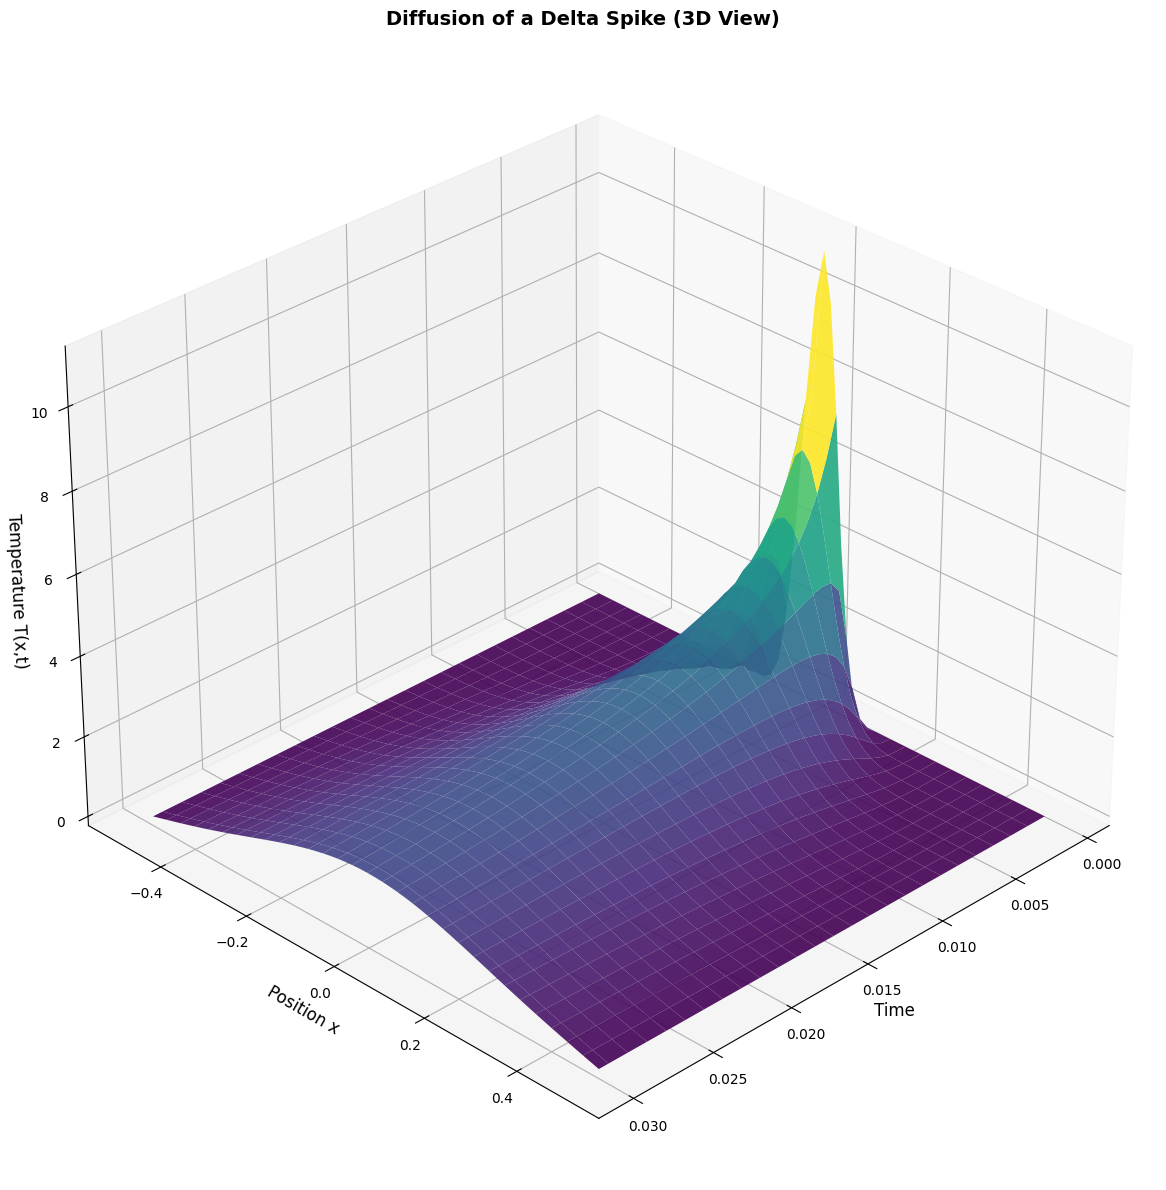

In [2]:
# Plot temperature versus x and t as a wire-mesh plot
fig = plt.figure(figsize=(12,12))
ax = fig.add_subplot(projection='3d')

Tp, Xp = np.meshgrid(tplot, xplot)
ax.plot_surface(Tp, Xp, ttplot, rstride=2, cstride=2, cmap=cm.viridis, alpha=0.9)

ax.set_xlabel('Time', fontsize=12)
ax.set_ylabel('Position x', fontsize=12)
ax.set_zlabel('Temperature T(x,t)', fontsize=12)
ax.set_title('Diffusion of a Delta Spike (3D View)', fontsize=14, fontweight='bold')
ax.view_init(elev=30, azim=45)

plt.tight_layout()
plt.show()

### Contour plot

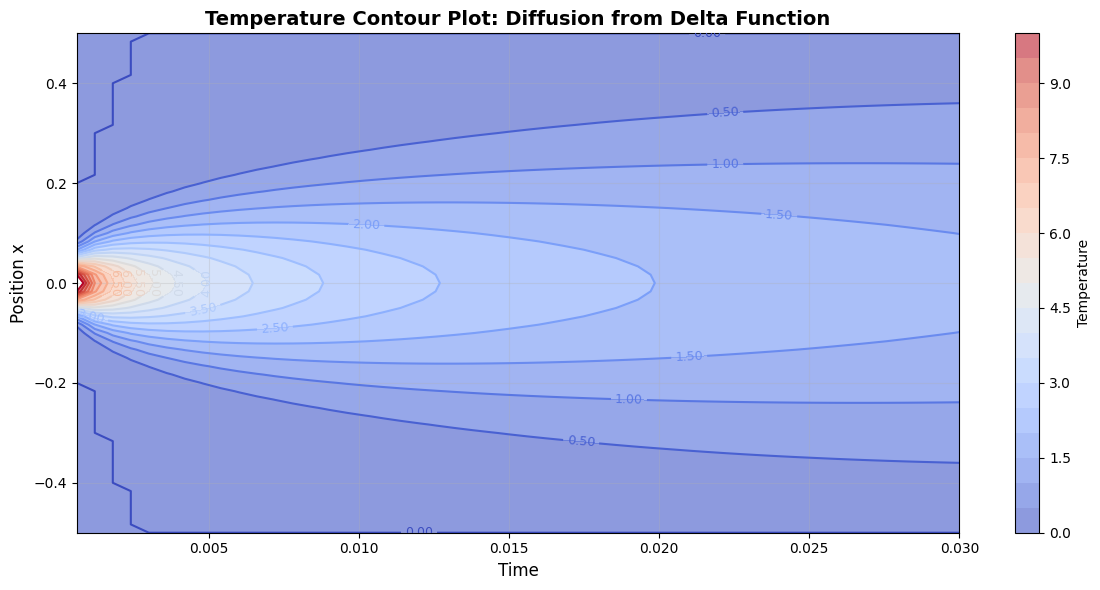

In [3]:
# Plot temperature versus x and t as a contour plot
fig, ax = plt.subplots(figsize=(12, 6))

levels = np.linspace(0., 10., num=21) 
ct = ax.contour(tplot, xplot, ttplot, levels=levels, cmap='coolwarm') 
ax.clabel(ct, fmt='%1.2f', fontsize=9)

# Add filled contours for better visualization
cf = ax.contourf(tplot, xplot, ttplot, levels=levels, cmap='coolwarm', alpha=0.6)
plt.colorbar(cf, ax=ax, label='Temperature')

ax.set_xlabel('Time', fontsize=12)
ax.set_ylabel('Position x', fontsize=12)
ax.set_title('Temperature Contour Plot: Diffusion from Delta Function', 
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Loop vs array slicing

The same update written with a loop over `i` and with array slicing.

In [4]:
import time

# Same parameters as dftcs above (N, h, coeff, nstep)
tt_loop = np.zeros(N);  tt_loop[int(N/2)] = 1./h
tt_vec  = np.zeros(N);  tt_vec[int(N/2)]  = 1./h

# Version 1: explicit loop over the interior grid points
start = time.perf_counter()
for istep in range(nstep):
    tt_new = tt_loop.copy()
    for i in range(1, N-1):
        tt_new[i] = tt_loop[i] + coeff*(tt_loop[i+1] + tt_loop[i-1] - 2*tt_loop[i])
    tt_loop = tt_new
t_loop = time.perf_counter() - start

# Version 2: array slicing (the line used in dftcs)
start = time.perf_counter()
for istep in range(nstep):
    tt_vec[1:(N-1)] = tt_vec[1:(N-1)] + coeff*(tt_vec[2:N] + tt_vec[0:(N-2)] - 2*tt_vec[1:(N-1)])
t_vec = time.perf_counter() - start

print("Same answer:", np.allclose(tt_loop, tt_vec))
print(f"Loop: {t_loop*1000:.1f} ms    Slicing: {t_vec*1000:.1f} ms")

Same answer: True
Loop: 12.1 ms    Slicing: 1.6 ms
